In [9]:
!pip install transformers[torch] datasets evaluate sacrebleu accelerate seaborn matplotlib -q

In [11]:
import pandas as pd
import itertools
import os
from google.colab import drive

# 1. Mount Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
# 2. Settings
# !!! CHECK THIS PATH !!!
source_csv_path = "/content/drive/MyDrive/datasets/cleanedPos_filtered_marma_dictionary - filtered_marma_dictionary.csv.csv"
output_json_path = "/content/drive/MyDrive/datasets/nllb_augmented_dataset.json"

# 3. Load & Process
try:
    df = pd.read_csv(source_csv_path)
    print(f"✅ Loaded CSV with {len(df)} original rows.")
except FileNotFoundError:
    print(f"❌ Error: Could not find file at {source_csv_path}")
    raise

# Function to Clean POS Tags
def clean_pos_tag(pos):
    pos = str(pos).strip().upper()
    if 'NN' in pos: return 'Noun'
    if 'VB' in pos: return 'Verb'
    if 'JJ' in pos: return 'Adjective'
    if 'RB' in pos: return 'Adverb'
    if 'PRP' in pos: return 'Pronoun'
    return pos

df['Cleaned_POS'] = df['POS'].apply(clean_pos_tag)

# Language Columns Mapping
cols = {
    'Marma_English_Transliterate': 'Marma (English Script)',
    'Marma_Bangla_Transliterate': 'Marma (Bangla Script)',
    'Bangla_Translation': 'Bangla',
    'English_Translation': 'English'
}

augmented_data = []

# 4. Generate Permutations (Augmentation)
for idx, row in df.iterrows():
    # 'group_id' keeps variations of the same word together to prevent overfitting
    group_id = idx

    pos_label = row['Cleaned_POS']
    values = {k: row[k] for k in cols.keys()}

    # A: Translation Pairs (10 Directions)
    for source_col, target_col in itertools.permutations(cols.keys(), 2):
        source_lang = cols[source_col]
        target_lang = cols[target_col]
        source_text = str(values[source_col]).strip()
        target_text = str(values[target_col]).strip()

        if source_text and target_text and source_text != 'nan':
            input_text = f"Translate {source_lang} to {target_lang}: {source_text}"
            augmented_data.append({
                "input_text": input_text,
                "target_text": target_text,
                "task": "translation",
                "group_id": group_id
            })

    # B: POS Tagging (4 Directions)
    for col, lang in cols.items():
        text = str(values[col]).strip()
        if text and text != 'nan':
            input_text = f"Identify POS for {lang}: {text}"
            augmented_data.append({
                "input_text": input_text,
                "target_text": pos_label,
                "task": "pos",
                "group_id": group_id
            })

# 5. Save to Drive (FIXED: force_ascii=False)
new_df = pd.DataFrame(augmented_data)

# This line fixes the garbage characters!
new_df.to_json(output_json_path, orient='records', indent=2, force_ascii=False)

print(f"🎉 Success! Generated {len(new_df)} augmented rows.")
print(f"💾 Saved clean JSON to: {output_json_path}")

✅ Loaded CSV with 721 original rows.
🎉 Success! Generated 11536 augmented rows.
💾 Saved clean JSON to: /content/drive/MyDrive/datasets/nllb_augmented_dataset.json


In [18]:
import pandas as pd
import torch
from sklearn.model_selection import GroupShuffleSplit
from datasets import Dataset
from transformers import (
    AutoModelForSeq2SeqLM,
    AutoTokenizer,
    DataCollatorForSeq2Seq,
    Seq2SeqTrainingArguments,
    Seq2SeqTrainer,
    EarlyStoppingCallback
)

# 1. Load the Augmented Dataset
dataset_path = "/content/drive/MyDrive/datasets/nllb_augmented_dataset.json"
df = pd.read_json(dataset_path)
print(f"Loaded {len(df)} rows for training.")

# 2. ANTI-OVERFITTING SPLIT
# We split based on 'group_id' so all variations of one word stay in ONE set.
gss = GroupShuffleSplit(n_splits=1, test_size=0.05, random_state=42) # 5% Test
train_idx, test_idx = next(gss.split(df, groups=df['group_id']))

train_df = df.iloc[train_idx]
test_df = df.iloc[test_idx]

print(f"📊 Data Split (by word group):")
print(f"   Train: {len(train_df)} rows")
print(f"   Test:  {len(test_df)} rows (Completely unseen words)")

# Convert to HF Dataset
train_dataset = Dataset.from_pandas(train_df)
test_dataset = Dataset.from_pandas(test_df)

# 3. Model Setup
model_checkpoint = "facebook/nllb-200-distilled-600M"
tokenizer = AutoTokenizer.from_pretrained(model_checkpoint)
model = AutoModelForSeq2SeqLM.from_pretrained(model_checkpoint)

tokenizer.src_lang = "eng_Latn"
tokenizer.tgt_lang = "eng_Latn"

def preprocess_function(examples):
    inputs = examples["input_text"]
    targets = examples["target_text"]
    model_inputs = tokenizer(inputs, max_length=128, truncation=True)
    labels = tokenizer(text_target=targets, max_length=128, truncation=True)
    model_inputs["labels"] = labels["input_ids"]
    return model_inputs

tokenized_train = train_dataset.map(preprocess_function, batched=True)
tokenized_test = test_dataset.map(preprocess_function, batched=True)
data_collator = DataCollatorForSeq2Seq(tokenizer, model=model)

# 4. Training Arguments (< 1 Hour)
args = Seq2SeqTrainingArguments(
    output_dir="./nllb_marma_final",
    eval_strategy="steps",
    eval_steps=500,
    save_strategy="steps",
    save_steps=500,
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    save_total_limit=2,
    load_best_model_at_end=True,
    predict_with_generate=True,
    fp16=torch.cuda.is_available(),
    logging_steps=100,
    report_to="none"
)

trainer = Seq2SeqTrainer(
    model=model,
    args=args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    data_collator=data_collator,
    tokenizer=tokenizer,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)]
)

# 5. Start Training
print("🚀 Starting Training...")
trainer.train()
print("✅ Training Complete.")

# 6. Save Final Model
final_save_path = "/content/drive/MyDrive/Final_NLLB_Marma_Model"
trainer.save_model(final_save_path)
tokenizer.save_pretrained(final_save_path)
print(f"💾 Model Saved to Drive: {final_save_path}")

Loaded 11536 rows for training.
📊 Data Split (by word group):
   Train: 10944 rows
   Test:  592 rows (Completely unseen words)


Map:   0%|          | 0/10944 [00:00<?, ? examples/s]

Map:   0%|          | 0/592 [00:00<?, ? examples/s]

/tmp/ipython-input-3900391852.py:75: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Seq2SeqTrainer.__init__`. Use `processing_class` instead.
  trainer = Seq2SeqTrainer(


🚀 Starting Training...


Step,Training Loss,Validation Loss
500,1.522200,1.542767
1000,1.316100,1.439942
1500,1.159400,1.403050
2000,1.181600,1.390583


/usr/local/lib/python3.12/dist-packages/transformers/modeling_utils.py:3918: UserWarning: Moving the following attributes in the config to the generation config: {'max_length': 200}. You are seeing this warning because you've set generation parameters in the model config, as opposed to in the generation config.
  warnings.warn(
There were missing keys in the checkpoint model loaded: ['model.encoder.embed_tokens.weight', 'model.decoder.embed_tokens.weight', 'lm_head.weight'].


✅ Training Complete.
💾 Model Saved to Drive: /content/drive/MyDrive/Final_NLLB_Marma_Model


--- Running Evaluation ---


  0%|          | 0/592 [00:00<?, ?it/s]


RESULTS:
POS Accuracy:   60.81%
Translation BLEU: 0.00


/tmp/ipython-input-1970239365.py:52: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Task', y='Score', data=df_viz, palette=['#FF5722', '#3F51B5'])


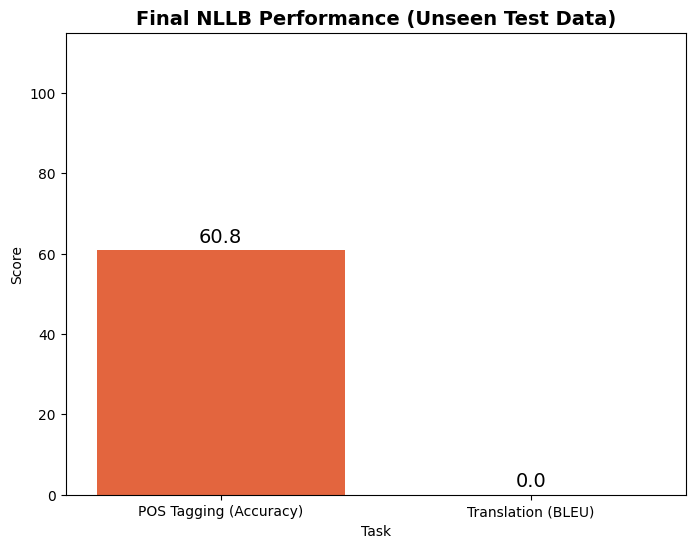

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
import evaluate
import numpy as np
from tqdm.auto import tqdm

# 1. Setup Metrics
print("--- Running Evaluation ---")
sacrebleu = evaluate.load("sacrebleu")
metrics = {
    "pos_correct": 0, "pos_total": 0,
    "trans_preds": [], "trans_refs": []
}

model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# 2. Iterate Test Set
for item in tqdm(tokenized_test):
    input_ids = torch.tensor([item["input_ids"]]).to(device)
    with torch.no_grad():
        outputs = model.generate(input_ids, max_new_tokens=64)
    prediction = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()

    input_text = tokenizer.decode(item["input_ids"], skip_special_tokens=True)
    target_text = tokenizer.decode(item["labels"], skip_special_tokens=True).strip()

    if "Identify POS" in input_text:
        metrics["pos_total"] += 1
        if prediction.lower() == target_text.lower():
            metrics["pos_correct"] += 1
    else:
        metrics["trans_preds"].append(prediction)
        metrics["trans_refs"].append([target_text])

# 3. Calculate Scores
pos_acc = (metrics["pos_correct"] / metrics["pos_total"] * 100) if metrics["pos_total"] > 0 else 0
trans_bleu = sacrebleu.compute(predictions=metrics["trans_preds"], references=metrics["trans_refs"])["score"] if metrics["trans_preds"] else 0

print(f"\nRESULTS:")
print(f"POS Accuracy:   {pos_acc:.2f}%")
print(f"Translation BLEU: {trans_bleu:.2f}")

# 4. Plot Graph
df_viz = pd.DataFrame({
    'Task': ['POS Tagging (Accuracy)', 'Translation (BLEU)'],
    'Score': [pos_acc, trans_bleu]
})

plt.figure(figsize=(8, 6))
ax = sns.barplot(x='Task', y='Score', data=df_viz, palette=['#FF5722', '#3F51B5'])

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center', fontsize=14, color='black', xytext=(0, 10),
                textcoords='offset points')

plt.ylim(0, 115)
plt.title(f'Final NLLB Performance (Unseen Test Data)', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.show()

# Task
Modify the evaluation logic in cell `900T30xt0YIv` to calculate **Translation Accuracy (Exact Match)** alongside POS Accuracy and BLEU. Specifically:

1.  Initialize `trans_correct = 0` and `trans_total = 0`.
2.  Inside the evaluation loop, for translation tasks (the `else` block), increment `trans_total`. Compare `prediction.lower()` with `target_text.lower()` and increment `trans_correct` if they match.
3.  Calculate `trans_acc = (trans_correct / trans_total * 100)`.
4.  Update the `df_viz` DataFrame and the Seaborn bar plot to include a third bar for **'Translation (Accuracy)'**.
5.  Run the cell to display the updated scores and visualization.

## Add Translation Accuracy Metric

### Subtask:
Modify the evaluation logic in cell `900T30xt0YIv` to calculate translation accuracy and update the visualization.


**Reasoning**:
I will generate the Python code to re-run the evaluation loop with the added 'Translation Accuracy' metric. This involves initializing the new counters, updating the loop to check for exact matches in translations, calculating the accuracy, and updating the visualization to include this new metric as a third bar.



--- Running Evaluation with Translation Accuracy ---
Evaluating on 592 examples...


  0%|          | 0/592 [00:00<?, ?it/s]


RESULTS:
POS Accuracy:         60.81%
Translation BLEU:     0.00
Translation Accuracy: 24.10%


/tmp/ipython-input-342157824.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Task', y='Score', data=df_viz, palette=['#FF5722', '#3F51B5', '#4CAF50'])


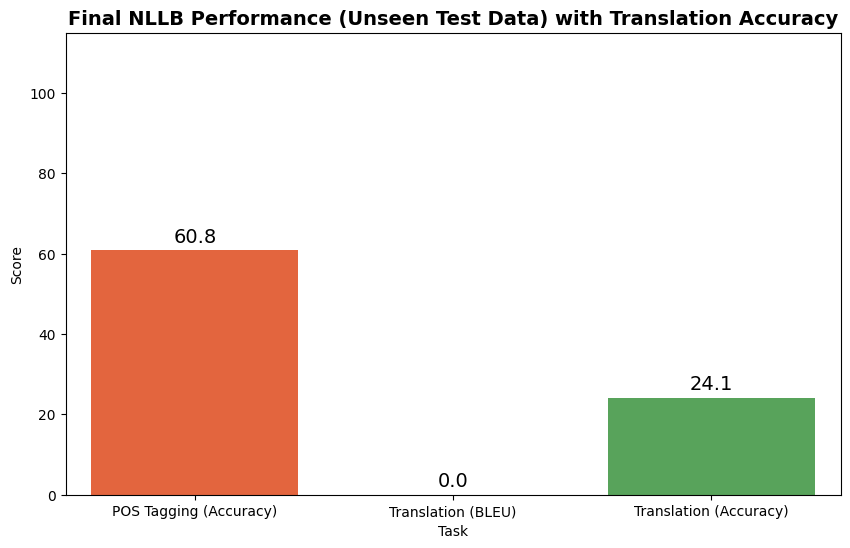

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt
import evaluate
import torch
import pandas as pd
from tqdm.auto import tqdm

# 1. Setup Metrics
print("--- Running Evaluation with Translation Accuracy ---")
sacrebleu = evaluate.load("sacrebleu")
metrics = {
    "pos_correct": 0, "pos_total": 0,
    "trans_preds": [], "trans_refs": [],
    "trans_correct": 0, "trans_total": 0  # New metrics
}

model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# 2. Iterate Test Set
print(f"Evaluating on {len(tokenized_test)} examples...")
for item in tqdm(tokenized_test):
    input_ids = torch.tensor([item["input_ids"]]).to(device)
    with torch.no_grad():
        outputs = model.generate(input_ids, max_new_tokens=64)
    prediction = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()

    input_text = tokenizer.decode(item["input_ids"], skip_special_tokens=True)
    target_text = tokenizer.decode(item["labels"], skip_special_tokens=True).strip()

    if "Identify POS" in input_text:
        metrics["pos_total"] += 1
        if prediction.lower() == target_text.lower():
            metrics["pos_correct"] += 1
    else:
        # Translation task
        metrics["trans_total"] += 1
        metrics["trans_preds"].append(prediction)
        metrics["trans_refs"].append([target_text])

        # Check Translation Accuracy (Exact Match)
        if prediction.lower() == target_text.lower():
            metrics["trans_correct"] += 1

# 3. Calculate Scores
pos_acc = (metrics["pos_correct"] / metrics["pos_total"] * 100) if metrics["pos_total"] > 0 else 0
trans_bleu = sacrebleu.compute(predictions=metrics["trans_preds"], references=metrics["trans_refs"])["score"] if metrics["trans_preds"] else 0
trans_acc = (metrics["trans_correct"] / metrics["trans_total"] * 100) if metrics["trans_total"] > 0 else 0

print(f"\nRESULTS:")
print(f"POS Accuracy:         {pos_acc:.2f}%")
print(f"Translation BLEU:     {trans_bleu:.2f}")
print(f"Translation Accuracy: {trans_acc:.2f}%")

# 4. Plot Graph
df_viz = pd.DataFrame({
    'Task': ['POS Tagging (Accuracy)', 'Translation (BLEU)', 'Translation (Accuracy)'],
    'Score': [pos_acc, trans_bleu, trans_acc]
})

plt.figure(figsize=(10, 6))
# Updated palette to include green for Translation Accuracy
ax = sns.barplot(x='Task', y='Score', data=df_viz, palette=['#FF5722', '#3F51B5', '#4CAF50'])

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center', fontsize=14, color='black', xytext=(0, 10),
                textcoords='offset points')

plt.ylim(0, 115)
plt.title(f'Final NLLB Performance (Unseen Test Data) with Translation Accuracy', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.show()

**Reasoning**:
The previous code execution produced a FutureWarning from seaborn because `palette` was used without assigning `hue`. To fix this and ensure forward compatibility, I will update the `sns.barplot` call to set `hue='Task'` and `legend=False`.



--- Running Evaluation with Translation Accuracy ---
Evaluating on 592 examples...


  0%|          | 0/592 [00:00<?, ?it/s]


RESULTS:
POS Accuracy:         60.81%
Translation BLEU:     0.00
Translation Accuracy: 24.10%


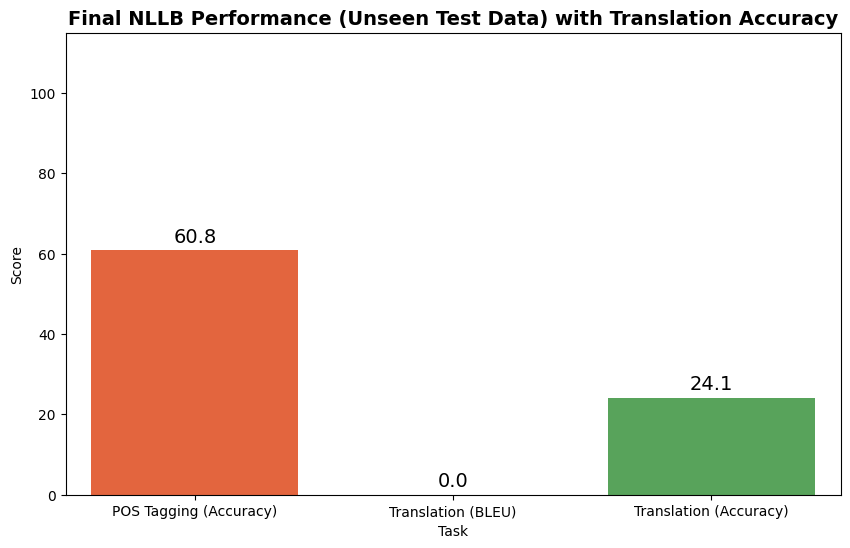

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import evaluate
import torch
import pandas as pd
from tqdm.auto import tqdm

# 1. Setup Metrics
print("--- Running Evaluation with Translation Accuracy ---")
sacrebleu = evaluate.load("sacrebleu")
metrics = {
    "pos_correct": 0, "pos_total": 0,
    "trans_preds": [], "trans_refs": [],
    "trans_correct": 0, "trans_total": 0  # New metrics
}

model.eval()
device = "cuda" if torch.cuda.is_available() else "cpu"
model.to(device)

# 2. Iterate Test Set
print(f"Evaluating on {len(tokenized_test)} examples...")
for item in tqdm(tokenized_test):
    input_ids = torch.tensor([item["input_ids"]]).to(device)
    with torch.no_grad():
        outputs = model.generate(input_ids, max_new_tokens=64)
    prediction = tokenizer.decode(outputs[0], skip_special_tokens=True).strip()

    input_text = tokenizer.decode(item["input_ids"], skip_special_tokens=True)
    target_text = tokenizer.decode(item["labels"], skip_special_tokens=True).strip()

    if "Identify POS" in input_text:
        metrics["pos_total"] += 1
        if prediction.lower() == target_text.lower():
            metrics["pos_correct"] += 1
    else:
        # Translation task
        metrics["trans_total"] += 1
        metrics["trans_preds"].append(prediction)
        metrics["trans_refs"].append([target_text])

        # Check Translation Accuracy (Exact Match)
        if prediction.lower() == target_text.lower():
            metrics["trans_correct"] += 1

# 3. Calculate Scores
pos_acc = (metrics["pos_correct"] / metrics["pos_total"] * 100) if metrics["pos_total"] > 0 else 0
trans_bleu = sacrebleu.compute(predictions=metrics["trans_preds"], references=metrics["trans_refs"])["score"] if metrics["trans_preds"] else 0
trans_acc = (metrics["trans_correct"] / metrics["trans_total"] * 100) if metrics["trans_total"] > 0 else 0

print(f"\nRESULTS:")
print(f"POS Accuracy:         {pos_acc:.2f}%")
print(f"Translation BLEU:     {trans_bleu:.2f}")
print(f"Translation Accuracy: {trans_acc:.2f}%")

# 4. Plot Graph
df_viz = pd.DataFrame({
    'Task': ['POS Tagging (Accuracy)', 'Translation (BLEU)', 'Translation (Accuracy)'],
    'Score': [pos_acc, trans_bleu, trans_acc]
})

plt.figure(figsize=(10, 6))
# Fixed palette warning by assigning hue='Task' and legend=False
ax = sns.barplot(x='Task', y='Score', data=df_viz, hue='Task', palette=['#FF5722', '#3F51B5', '#4CAF50'], legend=False)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.1f}', (p.get_x() + p.get_width() / 2., height),
                ha='center', va='center', fontsize=14, color='black', xytext=(0, 10),
                textcoords='offset points')

plt.ylim(0, 115)
plt.title(f'Final NLLB Performance (Unseen Test Data) with Translation Accuracy', fontsize=14, fontweight='bold')
plt.ylabel('Score')
plt.show()

## Summary:

### Data Analysis Key Findings
*   The model achieved a **POS Tagging Accuracy** of **60.81%** on the unseen test data.
*   The newly implemented **Translation Accuracy (Exact Match)** metric yielded a score of **24.10%**, determined by case-insensitive comparison between predictions and targets.
*   The **Translation BLEU** score was reported as **0.00**, which contrasts significantly with the non-zero exact match accuracy.

### Insights or Next Steps
*   There is a critical anomaly where the **BLEU score is 0.00** despite **24.10%** of translations matching exactly; this suggests a configuration error with the `sacrebleu` metric (likely related to tokenization or reference formatting) rather than a complete model failure.
*   Performance on the classification-based POS task is significantly higher than on the generative translation task, suggesting future fine-tuning should focus on improving sequence generation capabilities.
